# P5 — Deteksi Tepi SIMUTEH

Notebook ini mengikuti petunjuk praktikum P5-P6 SIMUTEH.

## Bagian 1 — Gradien dan operator tepi

In [1]:

from pathlib import Path
import json
import sys
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

root = Path.cwd()
if not (root / "src").exists():
    root = root.parent
sys.path.insert(0, str(root / "src"))

from utils_cv import baca, tampil
from praproses import praproses
from utils_tepi import tepi_acuan, skor_tepi, iou, mask_daun_awal, bercak_awal



PARAM = json.loads((root / "hasil" / "param_praproses.json").read_text(encoding="utf-8"))
label = pd.read_csv(root / "data" / "sintetis" / "label.csv")
hasil_dir = root / "hasil"
hasil_dir.mkdir(exist_ok=True)
pd.set_option("display.max_columns", 30)

def muat(nama):
    img = baca(str(root / "data" / "sintetis" / "citra" / nama))
    md = cv2.imread(str(root / "data" / "sintetis" / "mask_daun" / nama), 0)
    mb = cv2.imread(str(root / "data" / "sintetis" / "mask_bercak" / nama), 0)
    if md is None or mb is None:
        raise FileNotFoundError(f"Mask tidak lengkap untuk {nama}")
    return img, md, mb

img, md, mb = muat("teh_041.png")
pra = praproses(img, PARAM)
acuan = cv2.bitwise_or(tepi_acuan(md), tepi_acuan(mb))
print("Root:", root.name)
print("Jumlah citra:", len(label))


Root: Simuteh-1063
Jumlah citra: 60


### Langkah 1.1 — Lembar hitung manual

In [2]:

A = np.array([[52, 55, 180], [50, 58, 185], [54, 60, 190]], dtype=float)
sobel_x = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], dtype=float)
sobel_y = sobel_x.T
prewitt_x = np.array([[-1, 0, 1], [-1, 0, 1], [-1, 0, 1]], dtype=float)
prewitt_y = prewitt_x.T
laplace = np.array([[0, 1, 0], [1, -4, 1], [0, 1, 0]], dtype=float)

def hitung_manual(kx, ky):
    gx, gy = float((A * kx).sum()), float((A * ky).sum())
    return {"Gx": gx, "Gy": gy, "magnitudo": float(np.hypot(gx, gy)),
            "L1": abs(gx) + abs(gy),
            "arah_gradien": float(np.degrees(np.arctan2(gy, gx)))}

manual = pd.DataFrame([hitung_manual(sobel_x, sobel_y),
                       hitung_manual(prewitt_x, prewitt_y)],
                      index=["Sobel", "Prewitt"]).round(3)
manual["Laplacian"] = float((A * laplace).sum())
print(manual)
print("Arah tepi tegak lurus terhadap arah gradien.")


            Gx    Gy  magnitudo     L1  arah_gradien  Laplacian
Sobel    534.0  22.0    534.453  556.0         2.359      118.0
Prewitt  399.0  17.0    399.362  416.0         2.440      118.0
Arah tepi tegak lurus terhadap arah gradien.


### Langkah 1.2 — Gradien Sobel manual dan verifikasi OpenCV

Selisih maksimum Gx manual vs cv2.Sobel: 0.0


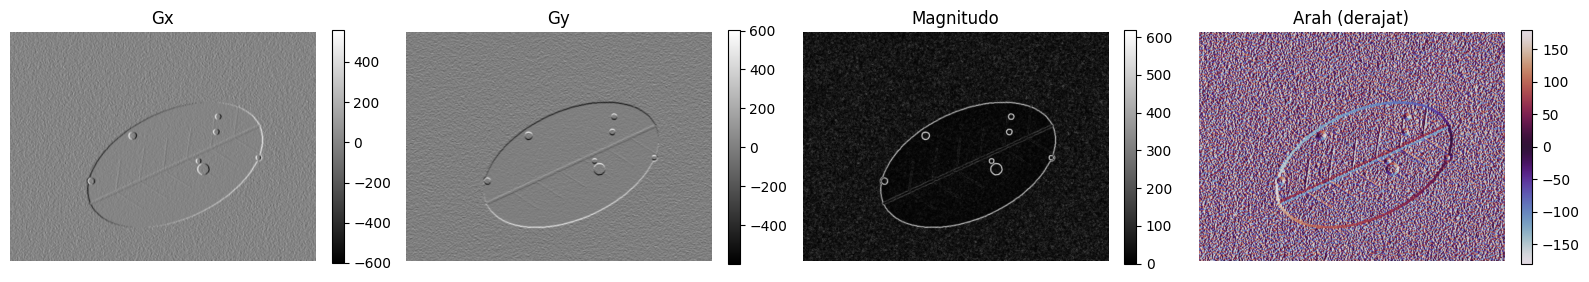

In [3]:

g = pra[:, :, 2].astype(np.float32)
gx = cv2.filter2D(g, cv2.CV_32F, sobel_x.astype(np.float32))
gy = cv2.filter2D(g, cv2.CV_32F, sobel_y.astype(np.float32))
mag = np.hypot(gx, gy)
arah = np.degrees(np.arctan2(gy, gx))
gx_cv = cv2.Sobel(g, cv2.CV_32F, 1, 0, ksize=3)
print("Selisih maksimum Gx manual vs cv2.Sobel:", float(np.abs(gx - gx_cv).max()))
fig, ax = plt.subplots(1, 4, figsize=(16, 3.5))
for a, c, judul in zip(ax, [gx, gy, mag, arah], ["Gx", "Gy", "Magnitudo", "Arah (derajat)"]):
    im = a.imshow(c, cmap="twilight" if judul.startswith("Arah") else "gray")
    a.set_title(judul); a.axis("off"); fig.colorbar(im, ax=a, fraction=0.035)
plt.tight_layout()
plt.show()


### Langkah 1.3–1.5 — Operator dan perbandingan menyeluruh

                             P      R     F1
sumber    kanal metode                      
mentah    Gray  Canny    0.758  0.750  0.753
                LoG      0.598  0.995  0.737
                Prewitt  0.780  0.973  0.858
                Sobel    0.743  0.976  0.833
          R     Canny    0.980  0.974  0.975
                LoG      0.877  0.995  0.919
                Prewitt  0.529  0.994  0.639
                Sobel    0.468  0.995  0.578
praproses Gray  Canny    0.667  0.945  0.776
                LoG      0.519  0.995  0.669
                Prewitt  0.525  0.995  0.677
                Sobel    0.492  0.995  0.644
          R     Canny    0.956  0.986  0.970
                LoG      0.812  0.996  0.878
                Prewitt  0.417  0.996  0.554
                Sobel    0.371  0.996  0.507


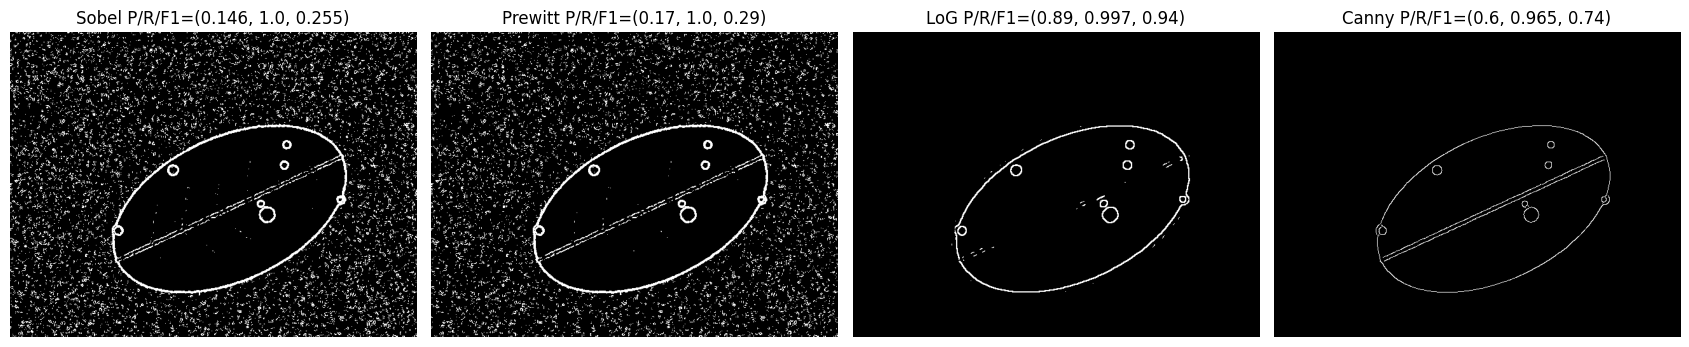

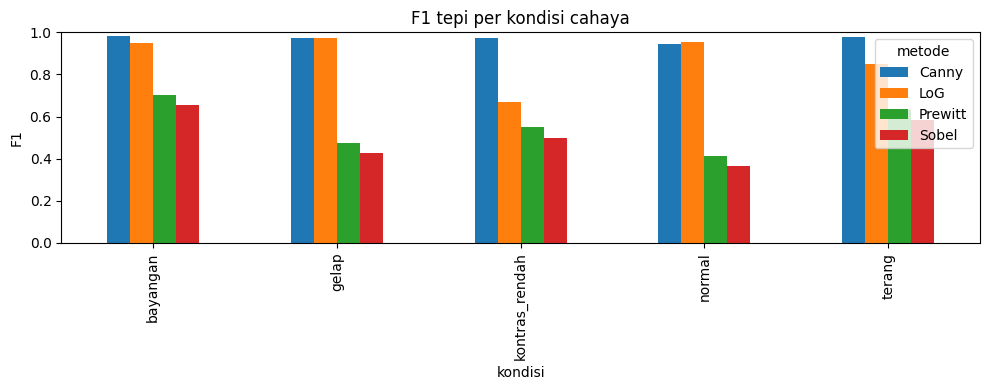

Tabel 6 - rerata F1 tepi per operator, kanal, dan sumber citra:
         Mentah, Gray  Mentah, R  Praproses, Gray  Praproses, R
metode                                                         
Sobel           0.833      0.578            0.644         0.507
Prewitt         0.858      0.639            0.677         0.554
LoG             0.737      0.919            0.669         0.878
Canny           0.753      0.975            0.776         0.970


In [4]:

def tepi_sobel(gray, T=100):
    gray = gray.astype(np.float32)
    m = np.hypot(cv2.Sobel(gray, cv2.CV_32F, 1, 0, ksize=3),
                cv2.Sobel(gray, cv2.CV_32F, 0, 1, ksize=3))
    return ((m > T) * 255).astype(np.uint8)

def tepi_prewitt(gray, T=75):
    gray = gray.astype(np.float32)
    gx = cv2.filter2D(gray, cv2.CV_32F, prewitt_x.astype(np.float32))
    gy = cv2.filter2D(gray, cv2.CV_32F, prewitt_y.astype(np.float32))
    return ((np.hypot(gx, gy) > T) * 255).astype(np.uint8)

def tepi_log(gray, sigma=3.0, frac=0.2):
    smooth = cv2.GaussianBlur(gray.astype(np.float32), (0, 0), sigma)
    lap = cv2.Laplacian(smooth, cv2.CV_32F)
    mn = cv2.erode(lap, np.ones((3, 3), np.float32))
    mx = cv2.dilate(lap, np.ones((3, 3), np.float32))
    kuat = mx - mn > frac * max(float(np.abs(lap).max()), 1e-6)
    return (((mn < 0) & (mx > 0) & kuat) * 255).astype(np.uint8)

def tepi_canny(gray, lo=30, hi=90, sigma=2.0):
    if sigma > 0:
        gray = cv2.GaussianBlur(gray, (0, 0), sigma)
    return cv2.Canny(gray, lo, hi)

metode = {"Sobel": tepi_sobel, "Prewitt": tepi_prewitt,
          "LoG": tepi_log, "Canny": tepi_canny}
g = pra[:, :, 2]
panel = {nama: fungsi(g) for nama, fungsi in metode.items()}
tampil(list(panel.values()), [f"{nama} P/R/F1={skor_tepi(e, acuan)}"
                              for nama, e in panel.items()],
       baris=1, ukuran=(17, 3.6))

baris = []
for _, d in label[label.kelas != "sehat"].iterrows():
    citra, md_i, mb_i = muat(d.nama_file)
    ac = cv2.bitwise_or(tepi_acuan(md_i), tepi_acuan(mb_i))
    for sumber, im in [("mentah", citra), ("praproses", praproses(citra, PARAM))]:
        for kanal, kanal_img in [("Gray", cv2.cvtColor(im, cv2.COLOR_BGR2GRAY)),
                                 ("R", im[:, :, 2])]:
            for nama, fungsi in metode.items():
                p, r, f1 = skor_tepi(fungsi(kanal_img), ac)
                baris.append([d.kondisi_cahaya, sumber, kanal, nama, p, r, f1])
tabel_tepi = pd.DataFrame(baris, columns=["kondisi", "sumber", "kanal", "metode", "P", "R", "F1"])
print(tabel_tepi.groupby(["sumber", "kanal", "metode"])[["P", "R", "F1"]].mean().round(3))
tabel_tepi.to_csv(hasil_dir / "p5_tabel_tepi.csv", index=False)
grafik = (tabel_tepi[(tabel_tepi.sumber == "praproses") & (tabel_tepi.kanal == "R")]
          .groupby(["kondisi", "metode"])["F1"].mean().unstack())
grafik.plot.bar(figsize=(10, 4), ylim=(0, 1), ylabel="F1", title="F1 tepi per kondisi cahaya")
plt.tight_layout(); plt.savefig(hasil_dir / "p5_f1_kondisi.png", dpi=150); plt.show()


ringkas_f1 = tabel_tepi.groupby(["sumber", "kanal", "metode"])["F1"].mean()
tabel6 = ringkas_f1.unstack(["sumber", "kanal"]).reindex(
    index=["Sobel", "Prewitt", "LoG", "Canny"],
    columns=[("mentah", "Gray"), ("mentah", "R"), ("praproses", "Gray"), ("praproses", "R")])
tabel6.columns = ["Mentah, Gray", "Mentah, R", "Praproses, Gray", "Praproses, R"]
print("Tabel 6 - rerata F1 tepi per operator, kanal, dan sumber citra:")
print(tabel6.round(3))
tabel6.round(3).to_csv(hasil_dir / "p5_tabel6_f1.csv")


## Bagian 2 — Canny dan keputusan pemakaian tepi

### Langkah 2.1 — NMS dan hysteresis secara manual

In [5]:
# NMS membandingkan tetangga searah gradien; hysteresis mempertahankan piksel lemah hanya bila terhubung ke piksel kuat.
def nms_tengah(magnitudo, arah):
    pusat = magnitudo[1, 1]
    if arah in (0, 180):
        tetangga = (magnitudo[1, 0], magnitudo[1, 2])
    elif arah == 90:
        tetangga = (magnitudo[0, 1], magnitudo[2, 1])
    elif arah == 45:
        tetangga = (magnitudo[0, 2], magnitudo[2, 0])
    elif arah == 135:
        tetangga = (magnitudo[0, 0], magnitudo[2, 2])
    else:
        raise ValueError(f"Arah NMS harus 0, 45, 90, atau 135, bukan {arah}")
    return bool(pusat >= max(tetangga))


M1 = np.array([[30, 40, 35], [90, 100, 95], [20, 30, 25]])
M2 = np.array([[50, 60, 55], [85, 80, 70], [40, 45, 50]])
print("NMS M1 (0 derajat):", nms_tengah(M1, 0))
print("NMS M1 (90 derajat):", nms_tengah(M1, 90))
print("NMS M2 (0 derajat):", nms_tengah(M2, 0))
print("NMS M2 (90 derajat):", nms_tengah(M2, 90))

nilai = np.array([20, 60, 120, 80, 40, 90, 30])
bawah, atas = 50, 100
kuat = nilai >= atas
lemah = (nilai >= bawah) & ~kuat
akhir = kuat.copy()
berubah = True
while berubah:  # piksel lemah ikut menjadi tepi bila bersebelahan dengan tepi akhir; rantai lemah ikut merambat
    berubah = False
    for i in np.flatnonzero(lemah & ~akhir):
        if np.any(akhir[max(0, i - 1):min(len(akhir), i + 2)]):
            akhir[i] = True
            berubah = True
print("Klasifikasi kuat:", kuat.astype(int).tolist())
print("Klasifikasi lemah:", lemah.astype(int).tolist())
print("Tepi akhir terhubung ke tepi kuat:", akhir.astype(int).tolist())

NMS M1 (0 derajat): True
NMS M1 (90 derajat): True
NMS M2 (0 derajat): False
NMS M2 (90 derajat): True
Klasifikasi kuat: [0, 0, 1, 0, 0, 0, 0]
Klasifikasi lemah: [0, 1, 0, 1, 0, 1, 0]
Tepi akhir terhubung ke tepi kuat: [0, 1, 1, 1, 0, 0, 0]


### Langkah 2.2–2.3 — Eksperimen ambang dan ambang otomatis

Rincian Tabel 7 per kondisi cahaya:
 sigma  ambang        kondisi     P     R    F1  R_bercak_berat  R_bercak_ringan
   0.0 100/200       bayangan 0.683 0.994 0.766           0.971            0.989
   0.0 100/200          gelap 0.388 0.992 0.496           0.962            0.995
   0.0 100/200 kontras_rendah 0.496 0.988 0.602           0.939            0.996
   0.0 100/200         normal 0.254 0.991 0.377           0.965            0.971
   0.0 100/200         terang 0.530 0.994 0.667           0.970            0.990
   0.0   30/90       bayangan 0.020 0.997 0.040           0.989            0.989
   0.0   30/90          gelap 0.018 0.996 0.035           0.974            1.000
   0.0   30/90 kontras_rendah 0.021 0.997 0.041           0.986            1.000
   0.0   30/90         normal 0.017 0.997 0.033           0.993            0.971
   0.0   30/90         terang 0.018 0.997 0.036           0.985            0.990
   0.0  50/150       bayangan 0.129 0.996 0.213           0.980          

Kode 2.2 - Canny otomatis vs tetap:
kondisi            bayangan  gelap  kontras_rendah  normal  terang
kanal ambang                                                      
Gray  otomatis        0.603  0.548           0.686   0.697   0.868
      tetap 30/90     0.754  0.732           0.927   0.725   0.740
R     otomatis        0.549  0.468           0.571   0.651   0.953
      tetap 30/90     0.982  0.973           0.971   0.942   0.979


Kode 2.3 - tepi palsu dalam daun sehat:
kanal            Gray      R
kondisi                     
bayangan        567.5    0.0
gelap           949.8    0.0
kontras_rendah  327.5    0.0
normal          888.8  176.0
terang          854.2  260.5


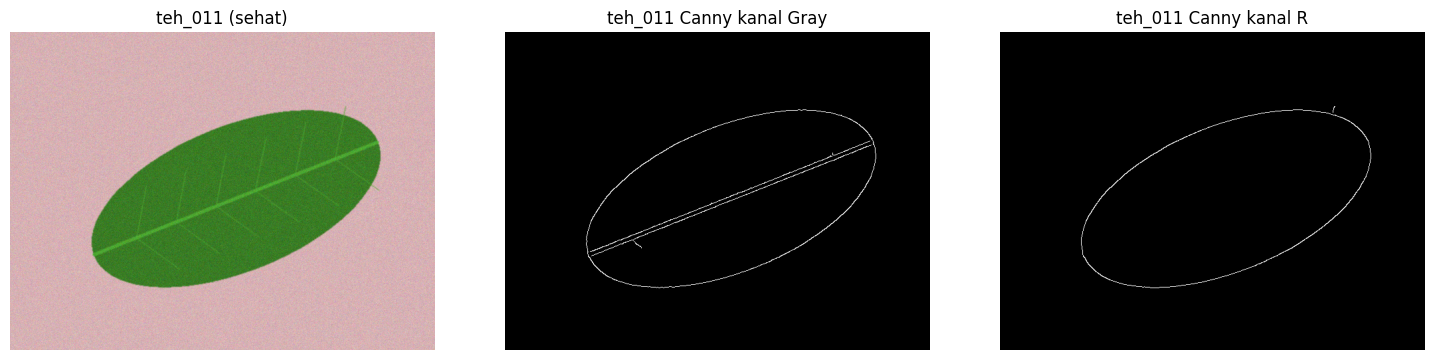

Gradien L1 di tepi daun dan ambang otomatis:
                      magnitudo_L1_tepi_daun  ambang_otomatis_bawah  \
kondisi        kanal                                                  
bayangan       Gray                    265.9                   74.2   
               R                       383.5                   79.8   
gelap          Gray                    288.4                   91.0   
               R                       450.4                  108.5   
kontras_rendah Gray                    177.0                   99.2   
               R                       222.9                  101.5   
normal         Gray                    317.6                  114.2   
               R                       453.5                  120.5   
terang         Gray                    262.1                  131.2   
               R                       347.2                  132.2   

                      ambang_otomatis_atas  
kondisi        kanal                        
bayangan    

In [6]:
baris = []
for _, d in label[label.kelas != "sehat"].iterrows():
    citra, md_i, mb_i = muat(d.nama_file)
    g_i = praproses(citra, PARAM)[:, :, 2]
    ac = cv2.bitwise_or(tepi_acuan(md_i), tepi_acuan(mb_i))
    ab = tepi_acuan(mb_i)
    for sigma in [0, 1.0, 2.0]:
        for lo, hi in [(30, 90), (50, 150), (100, 200)]:
            e = tepi_canny(g_i, lo, hi, sigma)
            p, r, f1 = skor_tepi(e, ac)
            baris.append([d.kelas, d.kondisi_cahaya, sigma, f"{lo}/{hi}", p, r, f1,
                          skor_tepi(e, ab)[1]])
canny = pd.DataFrame(
    baris, columns=["kelas", "kondisi", "sigma", "ambang", "P", "R", "F1", "R_bercak"]
)
print("Rincian Tabel 7 per kondisi cahaya:")
ringkas = canny.groupby(["sigma", "ambang", "kondisi"])[["P", "R", "F1"]].mean().reset_index()
r_bercak = canny.pivot_table(
    index=["sigma", "ambang", "kondisi"], columns="kelas", values="R_bercak", aggfunc="mean"
).reset_index().rename(columns={"berat": "R_bercak_berat", "ringan": "R_bercak_ringan"})
tabel7 = ringkas.merge(r_bercak, on=["sigma", "ambang", "kondisi"], how="left")
print(tabel7.round(3).to_string(index=False))
canny.to_csv(hasil_dir / "p5_canny_eksperimen.csv", index=False)
tabel7.to_csv(hasil_dir / "p5_f1_ambang_per_kondisi.csv", index=False)

tabel7_ringkas = canny.groupby(["sigma", "ambang"])[["P", "R", "F1"]].mean().join(
    canny.pivot_table(index=["sigma", "ambang"], columns="kelas", values="R_bercak")
    .rename(columns={"berat": "R_bercak_berat", "ringan": "R_bercak_ringan"}))
urut_tabel7 = [(s_, a_) for s_ in [0.0, 1.0, 2.0] for a_ in ["30/90", "50/150", "100/200"]]
tabel7_ringkas = tabel7_ringkas.loc[urut_tabel7].round(3)
print("\nTabel 7 (format petunjuk, rerata seluruh citra berbercak):")
print(tabel7_ringkas)
tabel7_ringkas.to_csv(hasil_dir / "p5_tabel7_canny.csv")


def canny_otomatis(gray, s=0.33):
    median = float(np.median(gray))
    lo = int(max(0, (1 - s) * median))
    hi = int(min(255, (1 + s) * median))
    return cv2.Canny(gray, lo, hi), lo, hi


baris = []
for _, d in label[label.kelas != "sehat"].iterrows():
    citra, md_i, mb_i = muat(d.nama_file)
    pra_i = praproses(citra, PARAM)
    ac = cv2.bitwise_or(tepi_acuan(md_i), tepi_acuan(mb_i))
    for kanal, gray in [("Gray", cv2.cvtColor(pra_i, cv2.COLOR_BGR2GRAY)),
                        ("R", pra_i[:, :, 2])]:
        e_auto, lo, hi = canny_otomatis(gray)
        baris.append([d.kondisi_cahaya, d.kelas, kanal, "otomatis",
                      skor_tepi(e_auto, ac)[2], float(np.median(gray)), lo, hi])
        e_tetap = tepi_canny(gray)
        baris.append([d.kondisi_cahaya, d.kelas, kanal, "tetap 30/90",
                      skor_tepi(e_tetap, ac)[2], float(np.median(gray)), 30, 90])
auto = pd.DataFrame(
    baris, columns=["kondisi", "kelas", "kanal", "ambang", "F1", "median",
                    "ambang_bawah", "ambang_atas"]
)
print("Kode 2.2 - Canny otomatis vs tetap:")
print(auto.groupby(["kanal", "ambang", "kondisi"])["F1"].mean().unstack("kondisi").round(3))
auto.to_csv(hasil_dir / "p5_canny_otomatis.csv", index=False)


baris, panel, judul = [], [], []
for _, d in label[label.kelas == "sehat"].iterrows():
    citra, md_i, _ = muat(d.nama_file)
    pra_i = praproses(citra, PARAM)
    dalam = cv2.erode(md_i, np.ones((7, 7), np.uint8)) > 0
    for kanal, gray in [("Gray", cv2.cvtColor(pra_i, cv2.COLOR_BGR2GRAY)),
                        ("R", pra_i[:, :, 2])]:
        e = tepi_canny(gray)
        baris.append([d.nama_file, d.kondisi_cahaya, kanal,
                      int(((e > 0) & dalam).sum())])
        if d.nama_file == "teh_011.png":
            panel.append(e)
            judul.append(f"teh_011 Canny kanal {kanal}")
sehat = pd.DataFrame(
    baris, columns=["nama", "kondisi", "kanal", "piksel_tepi_di_dalam_daun"]
)
print("Kode 2.3 - tepi palsu dalam daun sehat:")
print(sehat.groupby(["kondisi", "kanal"])["piksel_tepi_di_dalam_daun"].mean().unstack().round(1))
sehat.to_csv(hasil_dir / "p5_tepi_palsu.csv", index=False)
if panel:
    tampil([muat("teh_011.png")[0]] + panel, ["teh_011 (sehat)"] + judul,
           ukuran=(15, 3.6))
    plt.savefig(hasil_dir / "p5_tepi_palsu_teh011.png", dpi=150, bbox_inches="tight")
    plt.show()


baris = []
for _, d in label[label.kelas == "sehat"].iterrows():
    citra, md_i, _ = muat(d.nama_file)
    pra_i = praproses(citra, PARAM)
    for kanal, gray in [("Gray", cv2.cvtColor(pra_i, cv2.COLOR_BGR2GRAY)),
                        ("R", pra_i[:, :, 2])]:
        gx = cv2.Sobel(gray.astype(np.float32), cv2.CV_32F, 1, 0, ksize=3)
        gy = cv2.Sobel(gray.astype(np.float32), cv2.CV_32F, 0, 1, ksize=3)
        tepi_daun = tepi_acuan(md_i) > 0
        l1 = np.abs(gx) + np.abs(gy)
        _, lo, hi = canny_otomatis(gray)
        baris.append([d.nama_file, d.kondisi_cahaya, kanal,
                      float(l1[tepi_daun].mean()), lo, hi])
gradien_daun = pd.DataFrame(
    baris, columns=["nama", "kondisi", "kanal", "magnitudo_L1_tepi_daun",
                    "ambang_otomatis_bawah", "ambang_otomatis_atas"]
)
print("Gradien L1 di tepi daun dan ambang otomatis:")
print(gradien_daun.groupby(["kondisi", "kanal"]).mean(numeric_only=True).round(1))
gradien_daun.to_csv(hasil_dir / "p5_gradien_magnitudo_tepi_daun.csv", index=False)

### Langkah 2.4–2.6 — Ambang berbasis persentil dan tepi palsu

In [7]:
def canny_persentil(gray, q, rasio=0.4, sigma=2.0):
    smooth = cv2.GaussianBlur(gray.astype(np.float32), (0, 0), sigma)
    gx = cv2.Sobel(smooth, cv2.CV_32F, 1, 0, ksize=3)
    gy = cv2.Sobel(smooth, cv2.CV_32F, 0, 1, ksize=3)
    atas = float(np.percentile(np.hypot(gx, gy), q))
    return cv2.Canny(np.clip(smooth, 0, 255).astype(np.uint8), int(rasio * atas), int(atas))

baris, median_baris = [], []
for _, d in label[label.kelas != "sehat"].iterrows():
    citra, md_i, mb_i = muat(d.nama_file)
    pra_i = praproses(citra, PARAM)
    ac = cv2.bitwise_or(tepi_acuan(md_i), tepi_acuan(mb_i))
    for kanal, gray in [("Gray", cv2.cvtColor(pra_i, cv2.COLOR_BGR2GRAY)), ("R", pra_i[:, :, 2])]:
        median_baris.append([d.kondisi_cahaya, kanal, float(np.median(gray))])
        for q in [90, 95, 98]:
            e = canny_persentil(gray, q)
            p, r, f1 = skor_tepi(e, ac)
            baris.append([d.kondisi_cahaya, d.kelas, kanal, q, p, r, f1])
persentil = pd.DataFrame(baris, columns=["kondisi", "kelas", "kanal", "q", "P", "R", "F1"])
print("F1 Canny persentil per kondisi:")
print(persentil.groupby(["kanal", "q", "kondisi"])["F1"].mean().round(3))
persentil.to_csv(hasil_dir / "p5_canny_persentil.csv", index=False)
median_kanal = pd.DataFrame(median_baris, columns=["kondisi", "kanal", "median"])
print("Median per kanal-kondisi:")
print(median_kanal.pivot_table(index="kondisi", columns="kanal", values="median").round(2))
median_kanal.to_csv(hasil_dir / "p5_median_kanal_kondisi.csv", index=False)

baris = []
for _, d in label[label.kelas == "sehat"].iterrows():
    citra, md_i, _ = muat(d.nama_file)
    pra_i = praproses(citra, PARAM)
    gray = cv2.cvtColor(pra_i, cv2.COLOR_BGR2GRAY)
    tepi = tepi_canny(pra_i[:, :, 2])
    gradien = cv2.morphologyEx(md_i, cv2.MORPH_GRADIENT,
                               np.ones((3, 3), np.uint8),
                               borderType=cv2.BORDER_CONSTANT, borderValue=0)
    dalam = cv2.erode(md_i, np.ones((7, 7), np.uint8), borderType=cv2.BORDER_CONSTANT) > 0
    baris.append([d.kondisi_cahaya, float(np.mean(gradien > 0)), int(((tepi > 0) & dalam).sum()),
                  float(np.median(gray)), float(np.median(pra_i[:, :, 2]))])
gradien_daun = pd.DataFrame(baris, columns=["kondisi", "piksel_gradien_daun", "tepi_internal_R", "median_Gray", "median_R"])
print("Gradien tepi daun dan tepi internal:")
print(gradien_daun.groupby("kondisi").mean(numeric_only=True).round(2))
gradien_daun.to_csv(hasil_dir / "p5_gradien_tepi_daun.csv", index=False)


F1 Canny persentil per kondisi:
kanal  q   kondisi       
Gray   90  bayangan          0.064
           gelap             0.062
           kontras_rendah    0.051
           normal            0.057
           terang            0.053
       95  bayangan          0.300
           gelap             0.304
           kontras_rendah    0.101
           normal            0.258
           terang            0.170
       98  bayangan          0.738
           gelap             0.744
           kontras_rendah    0.697
           normal            0.726
           terang            0.737
R      90  bayangan          0.069
           gelap             0.064
           kontras_rendah    0.052
           normal            0.059
           terang            0.055
       95  bayangan          0.234
           gelap             0.108
           kontras_rendah    0.106
           normal            0.132
           terang            0.126
       98  bayangan          0.960
           gelap             0.9

Gradien tepi daun dan tepi internal:
                piksel_gradien_daun  tepi_internal_R  median_Gray  median_R
kondisi                                                                    
bayangan                       0.01              0.0       111.50    119.75
gelap                          0.01              0.0       136.50    163.00
kontras_rendah                 0.01              0.0       148.75    152.00
normal                         0.01            176.0       171.50    180.75
terang                         0.01            260.5       196.75    198.00


## Tabel 8. Keputusan pemakaian deteksi tepi pada SIMUTEH

Bukti hanya dari Bagian 1 dan 2: Tabel 6 = keluaran sel Kode 1.4, Tabel 7 = sel Kode 2.1, Kode 2.3 = tepi palsu pada daun sehat.

| Keperluan | Dipakai? | Operator dan parameter | Bukti |
|---|---|---|---|
| Menemukan batas daun | Ya, sebagai pembanding atau cadangan; mask daun utama tetap dari segmentasi | Canny kanal R sesudah praproses, σ = 2, ambang 30/90 | Tabel 6: F1 Canny kanal R 0,970 (mentah 0,975), jauh di atas Sobel 0,507, Prewitt 0,554, dan LoG 0,878. Tabel 7: pada σ = 2 dengan ambang 30/90, F1 berada di 0,942–0,982 pada kelima kondisi cahaya, sedangkan ambang 100/200 runtuh pada kontras_rendah (F1 0,123; R_bercak 0,000) |
| Menemukan batas bercak | Ya, sebagai kandidat kontur bercak | Canny kanal R, σ = 2, ambang 30/90 (alternatif σ = 1, ambang 100/200 dengan F1 0,978) | Tabel 7: recall tepi bercak 0,948 (berat 0,930; ringan 0,965) pada σ = 2 dengan ambang 30/90. Ambang 50/150 menurunkan R_bercak ringan menjadi 0,832 sehingga bercak kecil ikut hilang; σ = 0 menghasilkan presisi hanya 0,019–0,470 (derau ikut terdeteksi) |
| Mengisi wilayah bercak (segmentasi) | Tidak | – | Canny menghasilkan kontur selebar 1 piksel: tepi acuan hanya 0,545% dari seluruh piksel citra, sedangkan persen bercak membutuhkan luas wilayah. Luas diperoleh dari ambang median + k × MAD dan operasi morfologi pada P6 |
| Fitur bentuk bercak (P9) | Ya, sebagai calon fitur kontur | Canny kanal R, σ = 2, ambang 30/90 | Tabel 7 per kondisi: R_bercak 0,926–0,968 pada kelima kondisi (kontras_rendah 0,934), sehingga kontur bercak cukup lengkap. Wajib kanal R, bukan Gray: tepi palsu di dalam daun sehat 0–260,5 piksel pada kanal R dibanding 328–950 piksel pada kanal Gray (Kode 2.3) |

Catatan dari P6 (Kode 3.4): gradien morfologi pada mask daun mengungguli Canny pada empat dari lima kondisi cahaya, tetapi gagal pada kontras_rendah (F1 0,190 vs Canny 0,866), sehingga Canny tetap dibutuhkan sebagai pembanding batas daun.
